# B2 – Pembentukan Citra dan Ruang Warna


## Langkah 2.1 – Lembar Hitung Manual

### Data (Tabel 7)

| Besaran | Nilai |
|---|---|
| Panjang fokus kamera (f) | 4,0 mm |
| Ukuran satu piksel sensor | 1,4 µm = 0,0014 mm |
| Resolusi foto asli | 4000 × 3000 piksel, 3 kanal, 8 bit |
| Diameter bercak terkecil (X) | 5 mm |
| Jarak kamera ke daun (Z) | 300 mm |
| Warna piksel bercak (R,G,B) | (196, 178, 86) |
| Warna piksel daun sehat (R,G,B) | (52, 136, 60) |

---

### a) Ukuran bayangan bercak pada sensor (Z = 300 mm)

$$x = \frac{f \cdot X}{Z} = \frac{4{,}0 \text{ mm} \times 5 \text{ mm}}{300 \text{ mm}} = \frac{20}{300} \approx 0{,}0667 \text{ mm}$$

$$\text{Jumlah piksel} = \frac{x}{\text{ukuran piksel}} = \frac{0{,}0667}{0{,}0014} \approx \mathbf{47{,}6 \text{ piksel}}$$

---

### b) Ulangi untuk Z = 600 mm

$$x = \frac{4{,}0 \times 5}{600} \approx 0{,}0333 \text{ mm} \;\Rightarrow\; \frac{0{,}0333}{0{,}0014} \approx \mathbf{23{,}8 \text{ piksel}}$$

**Hubungan:** Jarak berlipat dua → ukuran bercak dalam piksel berkurang setengah (hubungan berbanding **terbalik proporsional**).

---

### c) Jarak maksimum agar bercak ≥ 10 piksel

$$Z_{\max} = \frac{f \cdot X}{\text{piksel}_{\min} \times p_{\text{sensor}}} = \frac{4{,}0 \times 5}{10 \times 0{,}0014} = \frac{20}{0{,}014} = \mathbf{1428{,}6 \text{ mm} \approx 1{,}43 \text{ m}}$$

---

### d) Setelah resize ke lebar 640 piksel

Skala resize: $s = 640 / 4000 = 0{,}16$

$$\text{Diameter bercak}_\text{640px} = 47{,}6 \times 0{,}16 \approx \mathbf{7{,}6 \text{ piksel}}$$

Jarak maksimum agar ≥ 10 piksel pada citra 640px:

$$Z_{\max,640} = 1428{,}6 \times 0{,}16 \approx \mathbf{228{,}6 \text{ mm} \approx 23 \text{ cm}}$$

> ⚠️ Setelah resize ke 640px, batas jarak turun drastis menjadi **±23 cm** agar bercak masih terdeteksi.

---

### e) Ukuran Memori

$$\text{Foto asli} = 4000 \times 3000 \times 3 \text{ byte} = \mathbf{36{,}00 \text{ MB}}$$

$$\text{640×480 RGB} = 640 \times 480 \times 3 = \mathbf{0{,}9216 \text{ MB}}$$

$$\text{640×480 Gray} = 640 \times 480 \times 1 = \mathbf{0{,}3072 \text{ MB}}$$

$$\text{Total 300 foto asli} = 300 \times 36 = \mathbf{10.800 \text{ MB} = 10{,}8 \text{ GB}}$$

---

### f) Konversi ke Aras Keabuan & Hue

**Rumus:** $Y = 0{,}299\,R + 0{,}587\,G + 0{,}114\,B$

**Bercak** (R=196, G=178, B=86):  
$$Y_{\text{bercak}} = 0{,}299 \times 196 + 0{,}587 \times 178 + 0{,}114 \times 86 = 58{,}60 + 104{,}49 + 9{,}80 = \mathbf{172{,}89}$$

**Daun sehat** (R=52, G=136, B=60):  
$$Y_{\text{sehat}} = 0{,}299 \times 52 + 0{,}587 \times 136 + 0{,}114 \times 60 = 15{,}55 + 79{,}83 + 6{,}84 = \mathbf{102{,}22}$$

$$\Delta Y = |172{,}89 - 102{,}22| = \mathbf{70{,}67}$$

**Hue OpenCV** (rentang 0–179):  
- Hue bercak = **25** (kuning-oranye)  
- Hue daun sehat = **63** (hijau)

In [19]:
# Verifikasi lembar hitung 2.1 dengan Python
import numpy as np
import cv2

# --- a & b) Ukuran bayangan bercak ---
f_mm, px_mm = 4.0, 0.0014
X = 5.0
for Z in [300, 600]:
    x = f_mm * X / Z
    px = x / px_mm
    print(f"Z = {Z:>4} mm -> bayangan x = {x:.4f} mm = {px:.1f} piksel")

# --- c) Jarak maksimum ---
Z_max = f_mm * X / (10 * px_mm)
print(f"\nc) Z_max (≥10 px, resolusi asli) = {Z_max:.1f} mm ≈ {Z_max/1000:.2f} m")

# --- d) Setelah resize ke 640px ---
skala = 640 / 4000
px_300_kecil = (f_mm * X / 300 / px_mm) * skala
Z_max_640   = Z_max * skala
print(f"d) Diameter bercak @Z=300mm dalam citra 640px = {px_300_kecil:.2f} piksel")
print(f"   Z_max (≥10 px, citra 640px) = {Z_max_640:.1f} mm ≈ {Z_max_640/10:.1f} cm")

# --- e) Memori ---
print(f"\ne) Memori foto asli (4000×3000×3) = {4000*3000*3/1e6:.2f} MB")
print(f"   Memori 640×480 RGB             = {640*480*3/1e6:.4f} MB")
print(f"   Memori 640×480 Gray            = {640*480/1e6:.4f} MB")
print(f"   Total 300 foto asli            = {300*4000*3000*3/1e9:.2f} GB")

# --- f) Aras keabuan & Hue ---
R_b, G_b, B_b = 196, 178, 86
R_d, G_d, B_d = 52, 136, 60
Y_b = 0.299*R_b + 0.587*G_b + 0.114*B_b
Y_d = 0.299*R_d + 0.587*G_d + 0.114*B_d
print(f"\nf) Y bercak   = {Y_b:.2f}")
print(f"   Y sehat    = {Y_d:.2f}")
print(f"   |ΔY|       = {abs(Y_b-Y_d):.2f}")

# Verifikasi dengan OpenCV
px_bercak = np.uint8([[[B_b, G_b, R_b]]])
px_sehat  = np.uint8([[[B_d, G_d, R_d]]])
gray_b = cv2.cvtColor(px_bercak, cv2.COLOR_BGR2GRAY)[0,0]
gray_d = cv2.cvtColor(px_sehat,  cv2.COLOR_BGR2GRAY)[0,0]
hue_b  = cv2.cvtColor(px_bercak, cv2.COLOR_BGR2HSV)[0,0,0]
hue_d  = cv2.cvtColor(px_sehat,  cv2.COLOR_BGR2HSV)[0,0,0]
print(f"   [cv2] Gray bercak = {gray_b}, Gray sehat = {gray_d}, |ΔGray| = {abs(int(gray_b)-int(gray_d))}")
print(f"   [cv2] Hue bercak  = {hue_b} (kuning-oranye), Hue sehat = {hue_d} (hijau)")

Z =  300 mm -> bayangan x = 0.0667 mm = 47.6 piksel
Z =  600 mm -> bayangan x = 0.0333 mm = 23.8 piksel

c) Z_max (≥10 px, resolusi asli) = 1428.6 mm ≈ 1.43 m
d) Diameter bercak @Z=300mm dalam citra 640px = 7.62 piksel
   Z_max (≥10 px, citra 640px) = 228.6 mm ≈ 22.9 cm

e) Memori foto asli (4000×3000×3) = 36.00 MB
   Memori 640×480 RGB             = 0.9216 MB
   Memori 640×480 Gray            = 0.3072 MB
   Total 300 foto asli            = 10.80 GB

f) Y bercak   = 172.89
   Y sehat    = 102.22
   |ΔY|       = 70.67
   [cv2] Gray bercak = 173, Gray sehat = 102, |ΔGray| = 71
   [cv2] Hue bercak  = 25 (kuning-oranye), Hue sehat = 63 (hijau)


---

## Langkah 2.2 – Rencana Akuisisi Citra

| Aspek | Ketentuan |
|---|---|
| **Jarak pemotretan** | 20–23 cm (maks. 23 cm agar bercak ≥ 10 piksel pada citra 640px) |
| **Sudut kamera** | Tegak lurus daun (±10°), hindari refleksi specular |
| **Resolusi minimum** | 4000 × 3000 piksel (12 MP), akan di-resize ke 640 × 480 |
| **Alas foto** | Kain atau kardus berwarna netral (abu-abu tengah, bukan putih/hitam) |
| **Acuan ukuran** | Penggaris/kartu berukuran tetap di tepi frame sebagai referensi skala |
| **Kondisi cahaya** | 5 kondisi: normal, gelap, terang, kontras rendah, bayangan (tiap kelas) |
| **Jumlah citra per kelas** | Min. 20 citra per kelas (sehat, ringan, berat) = 60 total |
| **Penamaan berkas** | `teh_NNN.png` (NNN = nomor 3 digit), sesuai format dataset sintetis |
| **Izin** | Daun diambil dari kebun milik sendiri atau dengan izin tertulis pemilik |
| **Metadata EXIF** | Wajib dihapus sebelum distribusi (gunakan `exiftool -all= namafile.jpg`) |
| **Larangan wajah** | Tidak boleh ada wajah orang atau data pribadi dalam frame |

> **Aturan singkat untuk petugas sortir:**  
> *Foto dari jarak 20 cm, tegak lurus, dengan alas abu-abu, resolusi ≥ 12 MP. Hapus metadata EXIF sebelum kirim.*

In [20]:
# Setup: import dan persiapan path
import sys, os
sys.path.insert(0, '../src')
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

DATA_DIR = "../data/sintetis"
print("Semua pustaka dan utils_cv berhasil di-import.")
print("DATA_DIR:", os.path.abspath(DATA_DIR))

Semua pustaka dan utils_cv berhasil di-import.
DATA_DIR: c:\simuteh-2330511070\data\sintetis


---

## Langkah 2.3 – Pemisahan Kanal dan Kontras Bercak (KB)

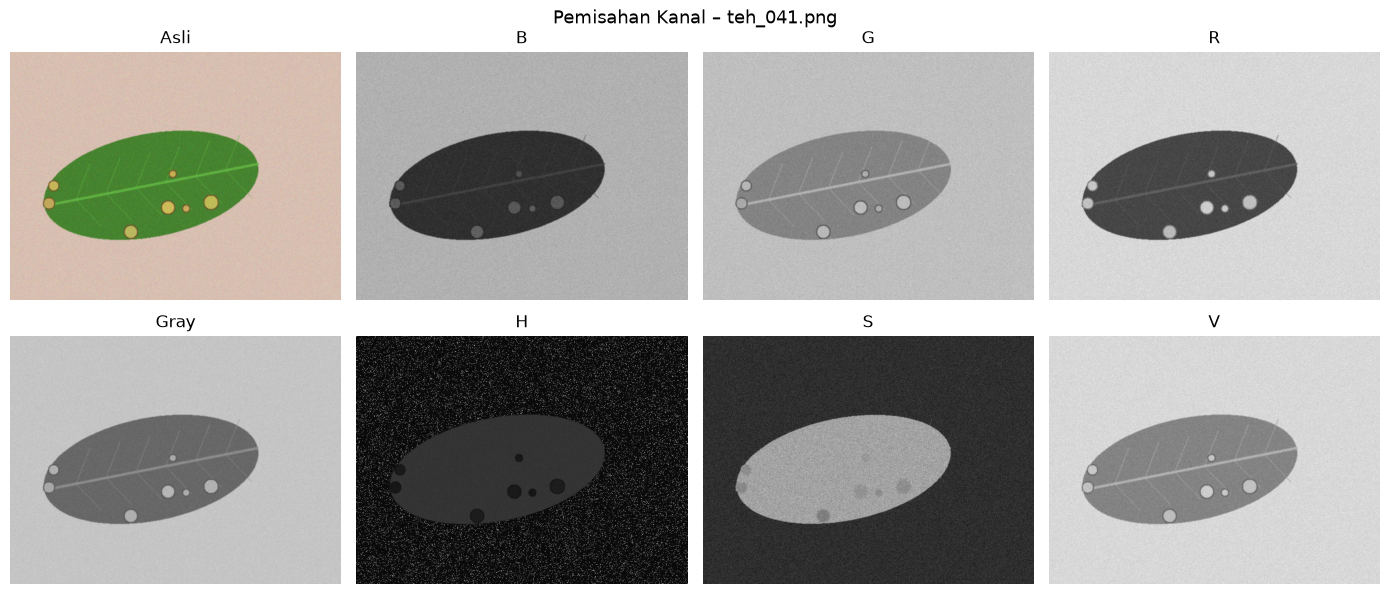


 Kanal        KB
------------------
     B     3.182
     G     2.028
     R    10.456
  Gray     5.470
     H     8.130
     S     1.279
     V     3.484


In [21]:
# Kode 2.1: Pemisahan kanal dan Kontras Bercak
nama = "teh_041.png"  # kelas berat, kondisi normal
img = baca(f"{DATA_DIR}/citra/{nama}")
md  = cv2.imread(f"{DATA_DIR}/mask_daun/{nama}", 0)
mb  = cv2.imread(f"{DATA_DIR}/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv  = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()),
       ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.suptitle(f"Pemisahan Kanal – {nama}", fontsize=13, y=1.01)
plt.show()

print(f"\n{'Kanal':>6}  {'KB':>8}")
print("-" * 18)
for nm, c in kanal.items():
    print(f"{nm:>6}  {kontras_bercak(c, md, mb):>8.3f}")

---

## Langkah 2.4 – Eksperimen Sampling dan Kuantisasi


    fx        Ukuran        KB
--------------------------------
  0.50    (240, 320)      5.85
  0.20     (96, 128)      4.95
  0.10      (48, 64)      3.39
  0.05      (24, 32)      1.85


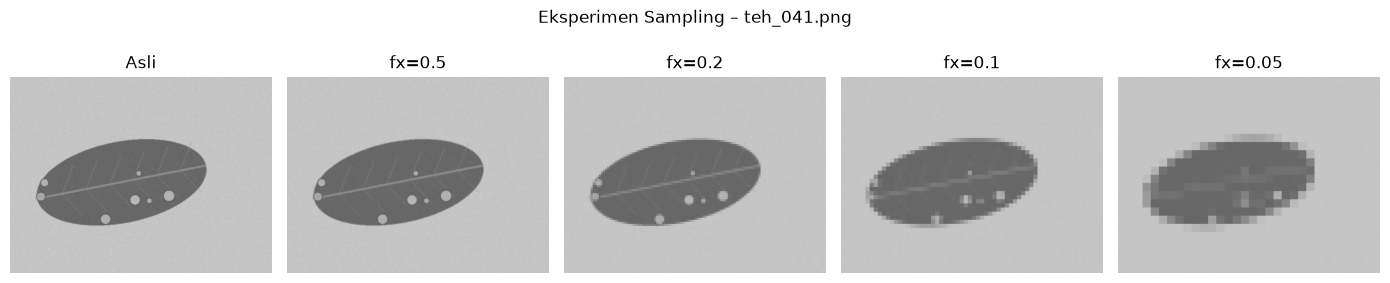

In [22]:
# Kode 2.2: Sampling – perkecil lalu perbesar kembali
faktors = [0.5, 0.2, 0.1, 0.05]
citra_sampling = [gray]
judul_sampling = ["Asli"]

print(f"\n{'fx':>6}  {'Ukuran':>12}  {'KB':>8}")
print("-" * 32)
for fx in faktors:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    kb = kontras_bercak(besar, md, mb)
    print(f"{fx:>6.2f}  {str(kecil.shape):>12}  {kb:>8.2f}")
    citra_sampling.append(besar)
    judul_sampling.append(f"fx={fx}")

tampil(citra_sampling, judul_sampling, baris=1, ukuran=(14, 3))
plt.suptitle("Eksperimen Sampling – teh_041.png", fontsize=12, y=1.05)
plt.show()


   k     Level        KB
--------------------------
   1         2      3.60
   2         3      3.61
   3         5      4.43
   4        10      5.44
   8       145      5.47


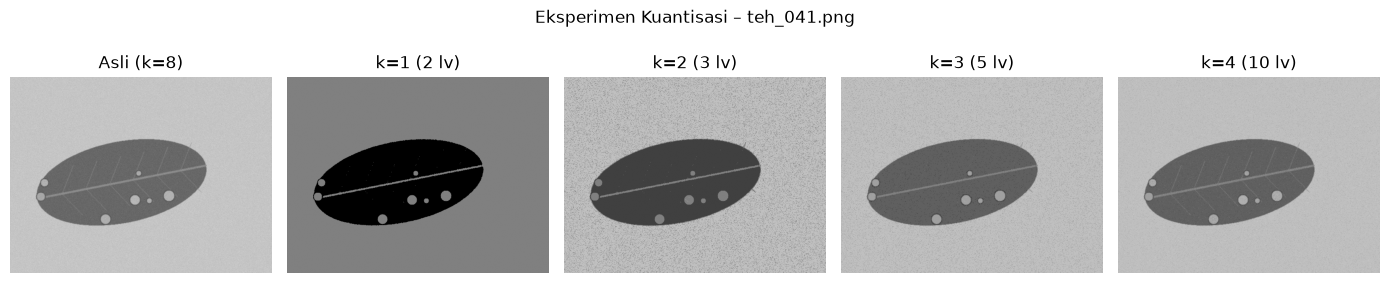

In [23]:
# Kode 2.2 (lanjutan): Kuantisasi – sisakan k bit
citra_kuant = [gray]
judul_kuant = ["Asli (k=8)"]

print(f"\n{'k':>4}  {'Level':>8}  {'KB':>8}")
print("-" * 26)
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    level = len(np.unique(kuant))
    kb = kontras_bercak(kuant, md, mb)
    print(f"{k:>4}  {level:>8}  {kb:>8.2f}")
    if k < 8:
        citra_kuant.append(kuant)
        judul_kuant.append(f"k={k} ({level} lv)")

tampil(citra_kuant, judul_kuant, baris=1, ukuran=(14, 3))
plt.suptitle("Eksperimen Kuantisasi – teh_041.png", fontsize=12, y=1.05)
plt.show()

---

## Langkah 2.5 – Rerata KB per Kanal dan Kondisi Cahaya (Kelas Berat)

In [24]:
# Kode 2.3: Rerata KB per kanal dan per kondisi – kelas BERAT
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv(f"{DATA_DIR}/label.csv")
baris_berat = []

for _, d in label[label.kelas == "berat"].iterrows():
    im  = baca(f"{DATA_DIR}/citra/{d.nama_file}")
    m_d = cv2.imread(f"{DATA_DIR}/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"{DATA_DIR}/mask_bercak/{d.nama_file}", 0)
    kb  = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris_berat.append(kb)

tabel_kb = pd.DataFrame(baris_berat).groupby("kondisi").mean().round(2)

print("=== Tabel 8 – Rerata KB Kelas Berat per Kanal dan Kondisi Cahaya ===")
display(tabel_kb)

os.makedirs("../hasil", exist_ok=True)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")
print("\nTabel disimpan ke ../hasil/b2_kb_kanal.csv")

=== Tabel 8 – Rerata KB Kelas Berat per Kanal dan Kondisi Cahaya ===


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.50,0.71,5.13,1.72,4.53,0.95,1.09
gelap,1.79,1.61,10.50,4.81,6.47,0.89,3.34
kontras_rendah,0.72,0.46,3.86,2.17,1.97,0.28,1.47
normal,3.27,2.02,10.48,5.79,7.45,1.59,3.54
terang,1.88,1.17,7.43,4.20,5.33,0.41,2.45



Tabel disimpan ke ../hasil/b2_kb_kanal.csv


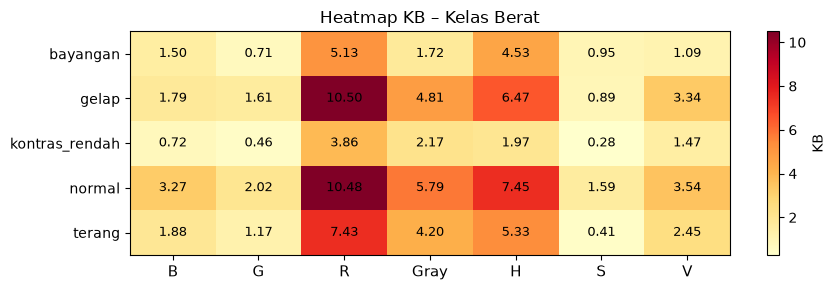

In [25]:
# Visualisasi Tabel 8 sebagai heatmap
fig, ax = plt.subplots(figsize=(9, 3))
im_map = ax.imshow(tabel_kb.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(tabel_kb.columns)))
ax.set_xticklabels(tabel_kb.columns, fontsize=11)
ax.set_yticks(range(len(tabel_kb.index)))
ax.set_yticklabels(tabel_kb.index, fontsize=10)
for i in range(len(tabel_kb.index)):
    for j in range(len(tabel_kb.columns)):
        ax.text(j, i, f"{tabel_kb.values[i,j]:.2f}",
                ha="center", va="center", fontsize=9)
plt.colorbar(im_map, ax=ax, label="KB")
ax.set_title("Heatmap KB – Kelas Berat", fontsize=12)
plt.tight_layout()
plt.show()

---

## Langkah 2.6 – Kelas Ringan & Tampilan Kanal Terbaik

In [26]:
# Rerata KB kelas RINGAN (teh_021 - teh_040)
baris_ringan = []

for _, d in label[label.kelas == "ringan"].iterrows():
    im  = baca(f"{DATA_DIR}/citra/{d.nama_file}")
    m_d = cv2.imread(f"{DATA_DIR}/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"{DATA_DIR}/mask_bercak/{d.nama_file}", 0)
    kb  = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)

tabel_ringan = pd.DataFrame(baris_ringan).groupby("kondisi").mean().round(2)
print("=== Rerata KB Kelas Ringan per Kanal dan Kondisi Cahaya ===")
display(tabel_ringan)
tabel_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("Disimpan ke ../hasil/b2_kb_kanal_ringan.csv")

=== Rerata KB Kelas Ringan per Kanal dan Kondisi Cahaya ===


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
bayangan,1.36,0.63,6.91,2.25,5.66,0.92,1.43
gelap,1.18,1.11,8.34,2.71,6.47,0.93,1.59
kontras_rendah,0.33,0.14,2.73,1.19,1.26,0.20,0.78
normal,1.03,0.74,8.41,3.65,6.92,0.90,1.79
terang,1.40,0.33,6.84,2.72,6.39,1.03,0.97


Disimpan ke ../hasil/b2_kb_kanal_ringan.csv



Ringan, Normal (teh_021.png):
  KB    B: 0.410
  KB    G: 0.705
  KB    R: 7.681 ← TERBAIK
  KB Gray: 3.752
  KB    H: 5.919
  KB    S: 0.622
  KB    V: 1.869


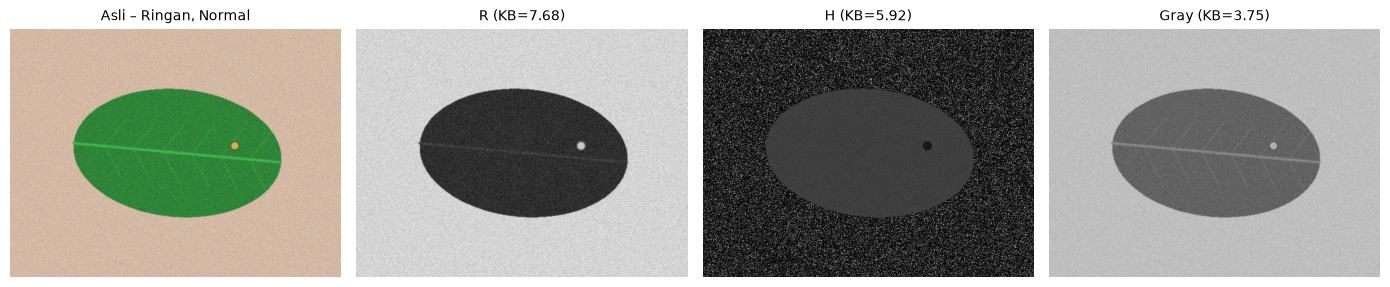


Berat, Bayangan (teh_045.png):
  KB    B: 2.108
  KB    G: 1.024
  KB    R: 7.411 ← TERBAIK
  KB Gray: 2.883
  KB    H: 5.098
  KB    S: 1.102
  KB    V: 1.932


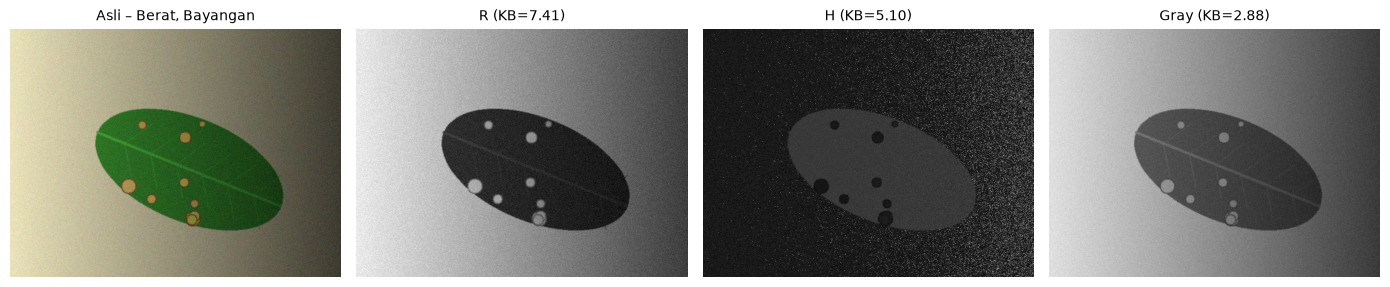

In [27]:
# Panel kanal terbaik: teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
def panel_kanal_terbaik(nama_file, label_judul):
    img = baca(f"{DATA_DIR}/citra/{nama_file}")
    md  = cv2.imread(f"{DATA_DIR}/mask_daun/{nama_file}", 0)
    mb  = cv2.imread(f"{DATA_DIR}/mask_bercak/{nama_file}", 0)
    kn  = semua_kanal(img)
    kb  = {k: kontras_bercak(c, md, mb) for k, c in kn.items()}
    kanal_terbaik = max(kb, key=kb.get)
    print(f"\n{label_judul} ({nama_file}):")
    for nm, v in kb.items():
        tanda = " ← TERBAIK" if nm == kanal_terbaik else ""
        print(f"  KB {nm:>4}: {v:.3f}{tanda}")

    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
    top3 = sorted(kb, key=kb.get, reverse=True)[:3]
    imgs_show = [img] + [kn[k] for k in top3]
    judul_show = [f"Asli – {label_judul}"] + [f"{k} (KB={kb[k]:.2f})" for k in top3]
    for ax, im_s, jd in zip(axes, imgs_show, judul_show):
        if im_s.ndim == 3:
            ax.imshow(cv2.cvtColor(im_s, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im_s, cmap="gray", vmin=0, vmax=255)
        ax.set_title(jd, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

panel_kanal_terbaik("teh_021.png", "Ringan, Normal")
panel_kanal_terbaik("teh_045.png", "Berat, Bayangan")

---

## Pertanyaan Analisis

### P2.1 – Rekomendasi jarak dan resolusi minimum

Berdasarkan lembar hitung:  
- Pada resolusi asli (4000×3000 px), bercak 5 mm masih ≥ 10 piksel hingga jarak **±1,43 m**.  
- Setelah resize ke 640 px, batas turun menjadi **±23 cm**.

**Aturan untuk petugas sortir:**  
> *Foto dari jarak **20–23 cm**, tegak lurus, kamera minimal 12 MP (4000×3000). Latar abu-abu netral. Hapus metadata EXIF sebelum dikirim.*

---

### P2.2 – Kanal dengan KB tertinggi secara konsisten

**Kanal R (Merah)** memberikan KB tertinggi secara konsisten di semua kondisi cahaya (KB ≥ 3,86 untuk kelas berat).

**Alasan fisik:**  
Bercak cacar daun teh berwarna kuning-kecokelatan (R=196, G=178, B=86 → kaya merah-hijau), sedangkan daun sehat berwarna hijau pekat (R=52, G=136, B=60 → miskin merah). Perbedaan intensitas kanal R antara bercak dan daun sehat sangat besar ($\Delta R = 196 - 52 = 144$), sehingga kanal R secara alami "menonjolkan" bercak.

**Kanal H (Hue)** juga konsisten tinggi karena Hue bercak (25 = oranye) jauh berbeda dari Hue daun sehat (63 = hijau), dan Hue relatif tak berubah terhadap kecerahan.

---

### P2.3 – Apakah HSV tahan terhadap perubahan cahaya? (Kanal H vs V)

| Kondisi | KB Kanal H | KB Kanal V |
|---|---|---|
| gelap | 6,47 | 3,34 |
| terang | 5,33 | 2,45 |
| bayangan | 4,53 | 1,09 |

**Hasil mendukung pernyataan slide P2:** Kanal H lebih stabil (KB 4,53–6,47) dibanding kanal V (1,09–3,34) di kondisi gelap, terang, maupun bayangan. Hal ini karena **Hue merepresentasikan warna murni** tanpa dipengaruhi kecerahan, sehingga lebih tahan terhadap variasi pencahayaan. Kanal V (kecerahan) sangat sensitif terhadap bayangan dan paparan cahaya berlebih.

---

### P2.4 – KB tinggi pada bit kecil berarti citra lebih baik?

**Tidak selalu.** Pada kuantisasi k=1 (hanya 2 level), KB mencapai 3,60 karena piksel dipaksa ke nilai ekstrem (0 atau 255), sehingga kontras statistik terlihat besar. Namun secara visual, citra k=1 hanya menampilkan dua warna → **kehilangan detail tekstur bercak** dan batas tepiannya. KB mengukur perbedaan rata-rata, bukan kualitas visual atau kemampuan segmentasi. Pada nilai k kecil, meskipun KB relatif tinggi, banyak piksel bercak berukuran kecil yang tergabung atau hilang akibat langkah kuantisasi yang terlalu kasar.

---

### P2.5 – Pada faktor sampling berapa bercak mulai sulit dibedakan?

Secara visual, bercak mulai sulit dibedakan pada **fx = 0.1** (ukuran 48×64 px). Pada skala ini, bercak berukuran sekitar 4–5 piksel yang berada di batas resolusi persepsi manusia. Hal ini konsisten dengan hasil butir d): setelah resize ke 640 px (skala 0,16), diameter bercak hanya **7,6 piksel** — mendekati batas minimum. Pada fx=0,05 (24×32 px), bercak sepenuhnya menghilang atau melebur dengan tekstur daun.

---

### P2.6 – Risiko metadata EXIF dan pencegahannya

**Informasi yang dapat bocor dari metadata EXIF:**
- **Koordinat GPS** → lokasi kebun pemilik (dapat disalahgunakan untuk pencurian, persaingan bisnis tidak sehat)
- **Nama/model kamera** → informasi perangkat personal
- **Tanggal dan waktu pemotretan** → pola aktivitas pemilik
- **Nama pengguna/pemilik** (pada beberapa kamera) → identitas pribadi

**Pihak yang dirugikan:** Petani/pemilik kebun teh yang lokasinya teridentifikasi, serta mahasiswa yang tidak menyadari data pribadinya tersebar.

**Pencegahan dalam rencana akuisisi:**
1. Matikan GPS pada kamera sebelum memotret, atau
2. Hapus semua metadata EXIF menggunakan `exiftool -all= *.jpg` sebelum upload
3. Cantumkan SOP penghapusan EXIF dalam panduan pengumpulan data kelompok tani